In [1]:
%matplotlib inline

In [2]:
%env SIT_ROOT=/sdf/group/lcls/ds/ana
%env SIT_PSDM_DATA=/sdf/data/lcls/ds
%env CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
%env SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/

env: SIT_ROOT=/sdf/group/lcls/ds/ana
env: SIT_PSDM_DATA=/sdf/data/lcls/ds
env: CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
env: SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/


## Imports

In [3]:
import numpy as np
import sys
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import socket
import pyFAI as pf
from pyFAI.gui import jupyter
from pyFAI.gui.jupyter.calib import Calibration

from tqdm import tqdm

import sys
from pathlib import Path

import ana_fun as ana

from utilities import *

print(f"PyFAI version {pf.version}")


Smalldata path exists: True
Jungfrau path exists: True
epix2 path exists: True
iq path exists: True
PyFAI version 0.21.3


### Estimations

Q estimation from distance or angle

In [4]:
def d_to_twotheta(d):
    """ calculate scattering angle """
    twotheta = np.arctan(d / sdd) # radiant
    return twotheta

def twotheta_to_q(twotheta):
    """ calculate momentum transfer q from the scattering angle """
    q = 4*np.pi / wavelength * np.sin(twotheta/2)*1e1 # in nm-1
    return q

In [16]:
twotheta_min = d_to_twotheta(beamstop_radius + 2*epix_pixel_size)
twotheta_max = d_to_twotheta(np.sqrt(epix_center[0]**2 + epix_center[1]**2) * epix_pixel_size)

qmin = twotheta_to_q(twotheta_min)
qmax = twotheta_to_q(twotheta_max)

print(f"The q range is: {qmin:.3f} - {qmax:.3f} 1/nm") 

The q range is: 0.018 - 0.278 1/nm


## Raw Data

In [7]:
import os

fpath=os.path.dirname(os.path.abspath("/sdf/data/lcls/ds/xpp/xppl1001021/results/smalldata_tools/arp_scripts/submit_smd_jungfrau.sh"))
fpathup = '/'.join(fpath.split('/')[:-1])
sys.path.append(fpathup)
print(f'\n{fpathup}')

from smalldata_tools.DetObject import DetObject


/sdf/data/lcls/ds/xpp/xppl1001021/results/smalldata_tools


ImportError: cannot import name 'dictToHdf5' from 'utilities' (/sdf/data/lcls/ds/xpp/xppl1001021/results/jason/utilities.py)

In [6]:
import psana

run = 190
ds = psana.MPIDataSource('exp=xppl1001021:run={}'.format(run))
#ds.break_after(100) # stop iteration after 3 events (break statements do not work reliably with MPIDataSource).
detname = 'jungfrau1M_alcove'
det = DetObject(detname, ds.env(), run, common_mode=None)

# nimg = 1000
# for nevt,evt in tqdm(enumerate(ds.events())):
#     if nevt == nimg: break
#     img = det.image(evt)
#     if nevt == 0:
#         imgs = np.zeros(np.r_[nimg, img.shape])
#     imgs[nevt] = det.image(evt)

ModuleNotFoundError: No module named 'smalldata_tools'

In [23]:
#np.save(f'{detname}_raw_img_run{run}', imgs.mean(axis = 0))

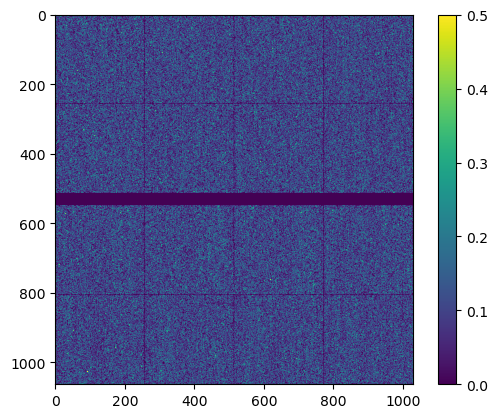

In [25]:
# img = np.load(Path(results, 'jason', f'{detname}_raw_img_run{run}.npy'))
plt.imshow(img.clip(0,1), vmax=0.5)
plt.colorbar()

In [ ]:
custom_f = Path(results, 'haoyuan/output/jungfrau1M_run_37.h5')
with h5py.File(custom_f) as h5:
    jg_imgs = np.empty(shape=(1000, 1064, 1030)) 
    for i in range(1000):
        jg_imgs[i] = h5[f'{i}'][:]
    

In [87]:
jg_img = jg_imgs.mean(0).clip(0,1)

In [95]:
np.save('jungfrau_run37_calib', jg_img)

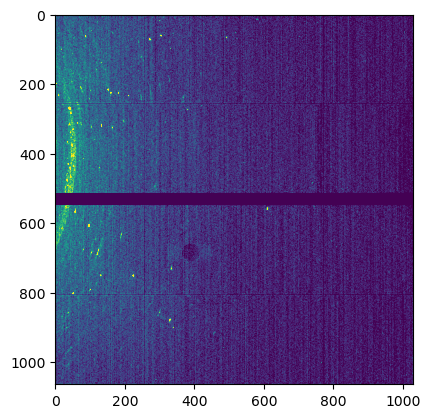

In [94]:
plt.imshow(jg_img, vmin=0.01, vmax=0.2)